In [97]:
import pandas as pd   
import numpy as np  
import matplotlib.pyplot as plt

In [98]:
df = pd.read_csv("Titanic-Dataset.csv")

In [99]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [100]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [101]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [102]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [103]:
df["Age"].isnull().sum()

177

In [104]:
df["Age"].max()

80.0

In [105]:
df["Age"].min()

0.42

In [106]:
mean = df["Age"].mean()
std = df["Age"].std()
zscores = (df["Age"] - mean) / std 
print(zscores)

0     -0.530005
1      0.571430
2     -0.254646
3      0.364911
4      0.364911
         ...   
886   -0.185807
887   -0.736524
888         NaN
889   -0.254646
890    0.158392
Name: Age, Length: 891, dtype: float64


In [107]:
df["outlair"] = zscores

In [108]:
df[df["Age"] == df["Age"].min()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,outlair
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,NaN,C,-2.015566


In [109]:
median = df["Age"].median()
mean = df["Age"].mean()
print(mean)
print(median)

29.69911764705882
28.0


In [110]:
df["Age"] = df["Age"].fillna(median)

In [111]:
df["Age"].isnull().sum()

0

In [112]:
df["Cabin"].isnull().sum()


687

In [113]:
df["Cabin"].head(10)

0     NaN
1     C85
2     NaN
3    C123
4     NaN
5     NaN
6     E46
7     NaN
8     NaN
9     NaN
Name: Cabin, dtype: str

In [114]:
df["Cabin"] = df["Cabin"].fillna("Unknown_Cabin")


In [115]:
df["Cabin"].isnull().sum()

0

In [116]:
df["Embarked"].isnull().sum()

2

In [117]:
df["Embarked"].head(10)

0    S
1    C
2    S
3    S
4    S
5    Q
6    S
7    S
8    S
9    C
Name: Embarked, dtype: str

In [118]:
em_mode =( df["Embarked"].mode()[0] )
print(em_mode)

S


In [119]:
df["Embarked"] = df["Embarked"].fillna(em_mode)

In [120]:
df["Embarked"].isnull().sum()


0

In [121]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin            0
Embarked         0
outlair        177
dtype: int64

In [122]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'outlair'],
      dtype='str')

In [123]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,outlair
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown_Cabin,S,-0.530005
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,0.571430
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown_Cabin,S,-0.254646
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,0.364911
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown_Cabin,S,0.364911
5,6,0,3,"Moran, Mr. James",male,28.0,0,0,330877,8.4583,Unknown_Cabin,Q,NaN
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,1.672866
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,Unknown_Cabin,S,-1.906799
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,Unknown_Cabin,S,-0.185807
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,Unknown_Cabin,C,-1.080723


In [124]:
df["Sex"].unique()

<StringArray>
['male', 'female']
Length: 2, dtype: str

In [125]:
df["Name"] = df['Name'].str.strip()

In [126]:
mean_fare = df["Fare"].mean()
std_fare = df["Fare"].std()
zscores = (df["Fare"] - mean_fare) / std_fare
print(zscores)

0     -0.502163
1      0.786404
2     -0.488580
3      0.420494
4     -0.486064
         ...   
886   -0.386454
887   -0.044356
888   -0.176164
889   -0.044356
890   -0.492101
Name: Fare, Length: 891, dtype: float64


In [127]:
outliers = zscores[(zscores > 3) | (zscores < -3)]
print(outliers)

27     4.644393
88     4.644393
118    4.332899
258    9.661740
299    4.332899
311    4.631815
341    4.644393
377    3.608038
380    3.930516
438    4.644393
527    3.814891
557    3.930516
679    9.661740
689    3.604768
700    3.930516
716    3.930516
730    3.604768
737    9.661740
742    4.631815
779    3.604768
Name: Fare, dtype: float64


In [128]:
df.loc[zscores.abs() > 3, ["Name", "Pclass", "Fare"]]

,Name,Pclass,Fare
27,"Fortune, Mr. Charles Alexander",1,263.0000
88,"Fortune, Miss. Mabel Helen",1,263.0000
118,"Baxter, Mr. Quigg Edmond",1,247.5208
258,"Ward, Miss. Anna",1,512.3292
299,"Baxter, Mrs. James (Helene DeLaudeniere Chaput)",1,247.5208
311,"Ryerson, Miss. Emily Borie",1,262.3750
341,"Fortune, Miss. Alice Elizabeth",1,263.0000
377,"Widener, Mr. Harry Elkins",1,211.5000
380,"Bidois, Miss. Rosalie",1,227.5250
438,"Fortune, Mr. Mark",1,263.0000


In [129]:
df["Fare"] = df["Fare"].replace(0, np.nan)

In [130]:
df['Fare'].isnull().sum()

15

In [131]:
df["Fare"] = df["Fare"].fillna(df.groupby("Pclass")["Fare"].transform("median"))

In [132]:
df['Fare'].isnull().sum()

0

In [133]:
save = df.to_csv("Clean_Titanic_Data.csv" , index= False)

In [134]:
survival = df["Survived"].value_counts()
survival

Survived
0    549
1    342
Name: count, dtype: int64

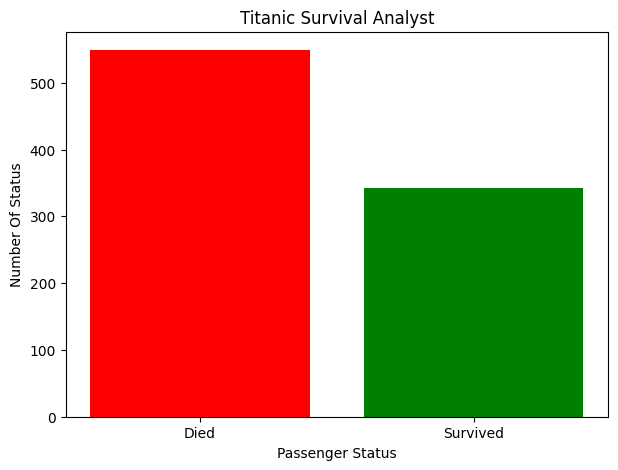

In [135]:
plt.figure(figsize=(7,5))
plt.bar([
    "Died","Survived"
],survival.values,color=["red","green"])
plt.title("Titanic Survival Analyst")
plt.xlabel("Passenger Status")
plt.ylabel("Number Of Status")
plt.show()

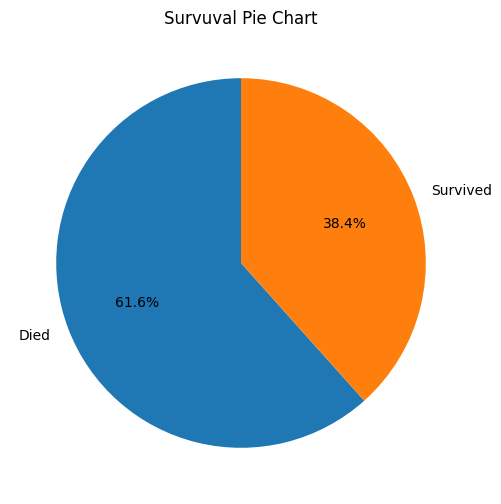

In [136]:
plt.figure(figsize=(6,6))
plt.pie(
    survival.values,
    labels=["Died","Survived"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Survuval Pie Chart")
plt.show()

In [137]:
gender = df["Sex"].value_counts()
gender

Sex
male      577
female    314
Name: count, dtype: int64

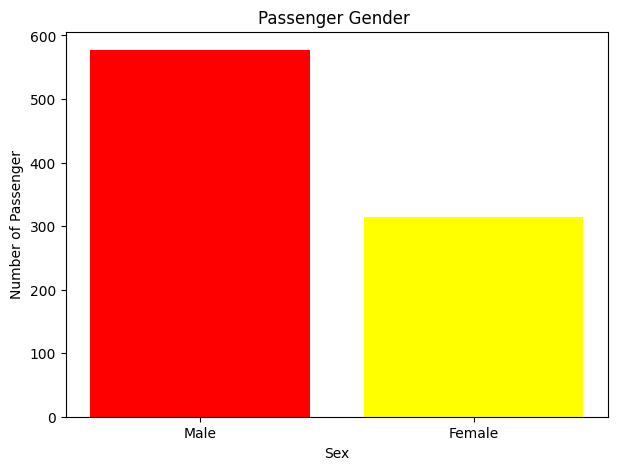

In [138]:
plt.figure(figsize=(7,5))
plt.bar(["Male","Female"],gender.values,color=["red","yellow"])
plt.title("Passenger Gender ")
plt.xlabel("Sex")
plt.ylabel("Number of Passenger")
plt.show()

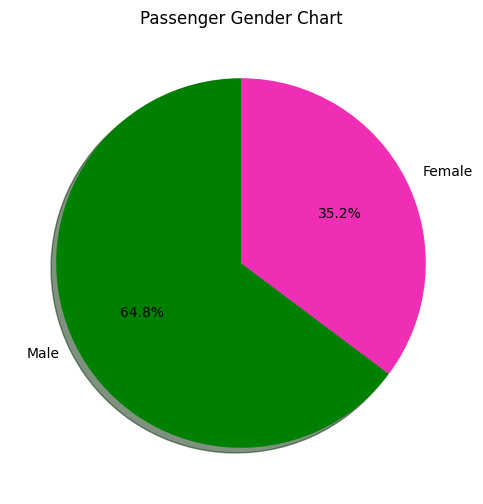

In [139]:
plt.figure(figsize=(6,6))
plt.pie(gender.values,
        labels=["Male","Female"],
        autopct="%1.1f%%",
        startangle=90,
        shadow=True,
        colors=["green","#f02eb5"])

plt.title("Passenger Gender Chart")
plt.show()

In [140]:
age_mean= df["Age"].mean()
age_max = df["Age"].max()
age_min = df["Age"].min()
age_count = df["Age"].count()

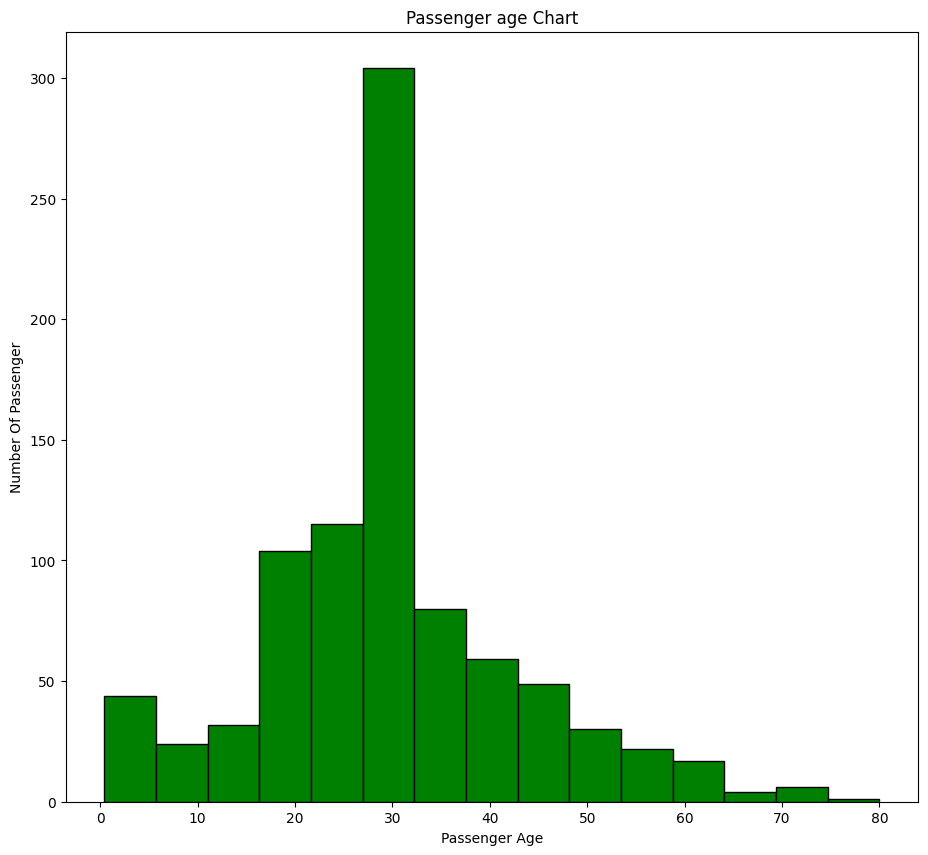

In [141]:
plt.figure(figsize=(11,10))
plt.hist(df["Age"].dropna(),
         bins=15,
         color="green",
         edgecolor="black")
plt.title("Passenger age Chart")
plt.xlabel("Passenger Age")
plt.ylabel("Number Of Passenger")
plt.show()

In [142]:
class_ticket = df["Pclass"].value_counts()
class_ticket

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

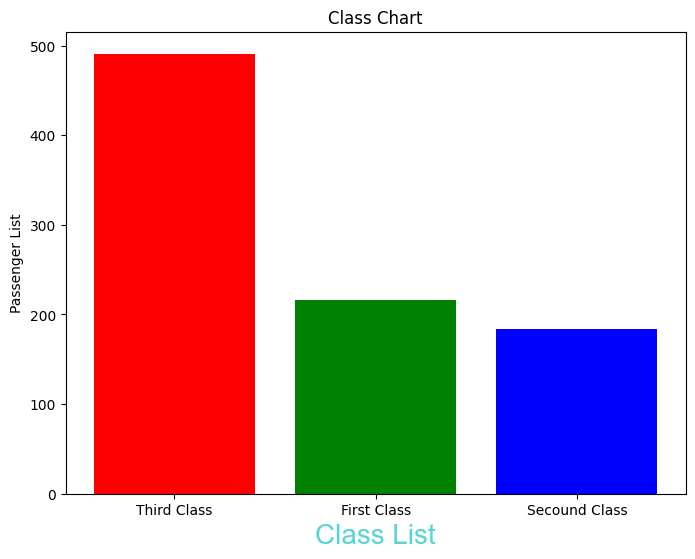

In [143]:
plt.figure(figsize=(8,6))
plt.bar(["Third Class","First Class","Secound Class"],
        class_ticket.values,
        color=["red","Green","blue"])

plt.title("Class Chart")
plt.xlabel("Class List",color="#57d4d4",font="arial",size=20)
plt.ylabel("Passenger List")
plt.show()

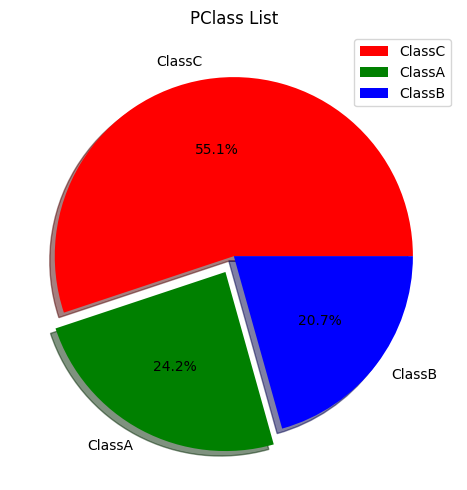

In [144]:
plt.figure(figsize=(8,5))
plt.pie(class_ticket.values,
        labels=["ClassC","ClassA","ClassB"],
        autopct="%1.1f%%",
        colors=["red","green","blue"],
        explode=(0,0.1,0),
        shadow=True,
        )
plt.title("PClass List")
plt.legend()
plt.tight_layout()
plt.show()

In [145]:
ticket_mean = df["Fare"].mean()
ticket_max = df["Fare"].max()
ticket_min = df["Fare"].min()
ticket_count = df["Fare"].count()

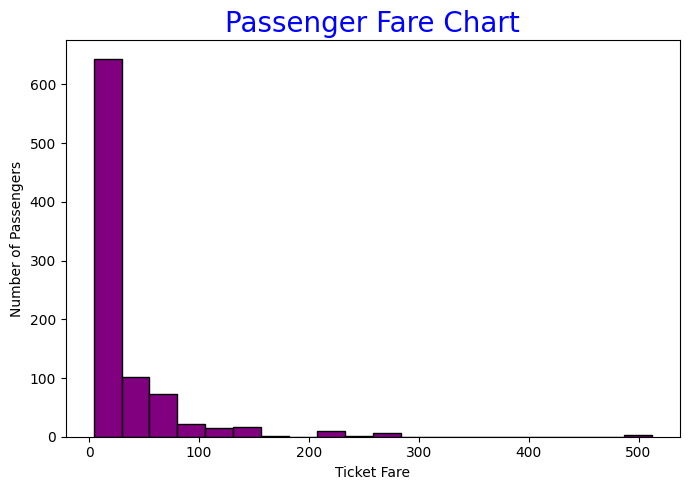

In [146]:
plt.figure(figsize=(7,5))
plt.hist(df["Fare"].dropna(),
         bins=20,
         color="purple",
         edgecolor="black")
plt.title("Passenger Fare Chart",size=20,color="blue")
plt.xlabel("Ticket Fare")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

In [147]:
df.groupby("Sex")["Survived"].value_counts()

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64

In [148]:
df.groupby("Sex")["Survived"].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

In [149]:
pd.crosstab(df["Sex"], df["Survived"])

Survived,0,1
Sex,,
female,81,233
male,468,109


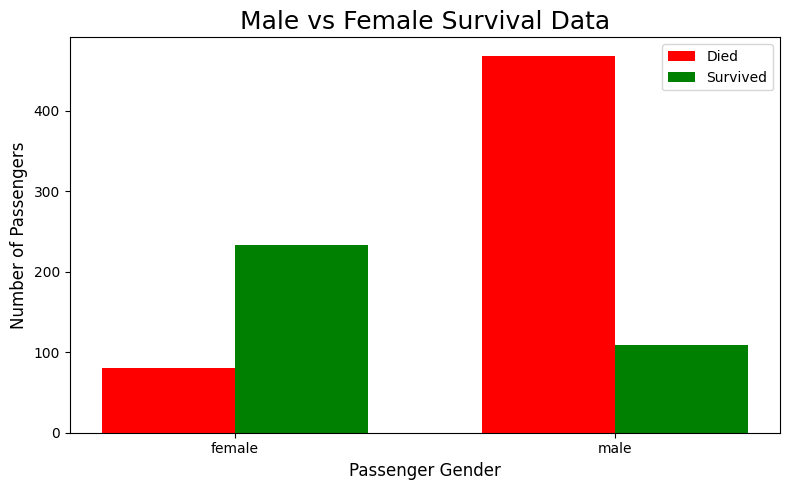

In [150]:

survival_data = pd.crosstab(df["Sex"], df["Survived"])
plt.figure(figsize=(8,5))
x = np.arange(len(survival_data.index))
width = 0.35
plt.bar(
    x - width/2,
    survival_data[0],
    width,
    label="Died",
    color="red"
)
plt.bar(
    x + width/2,
    survival_data[1],
    width,
    label="Survived",
    color="green"
)
plt.xticks(x, survival_data.index)
plt.title("Male vs Female Survival Data", size=18)
plt.xlabel("Passenger Gender", size=12)
plt.ylabel("Number of Passengers", size=12)
plt.legend()
plt.tight_layout()
plt.show()


In [151]:
df.groupby("Pclass")["Survived"].value_counts()

Pclass  Survived
1       1           136
        0            80
2       0            97
        1            87
3       0           372
        1           119
Name: count, dtype: int64

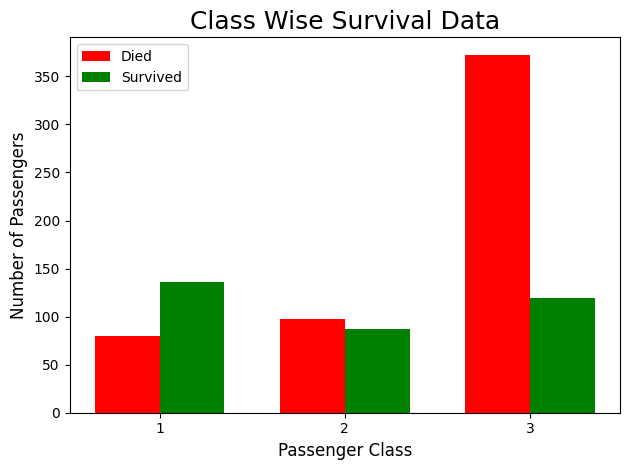

In [152]:
survival = pd.crosstab(df["Pclass"],df["Survived"])
x = np.arange(len(survival.index))
width = 0.35

plt.bar(
    x - width/2,
    survival[0],
    width,
    label="Died",
    color="red"
)

plt.bar(
    x + width/2,
    survival[1],
    width,
    label="Survived",
    color="green"
)

plt.xticks(x , survival.index)
plt.title("Class Wise Survival Data", size=18)
plt.xlabel("Passenger Class", size=12)
plt.ylabel("Number of Passengers", size=12)
plt.legend()
plt.tight_layout()
plt.show()

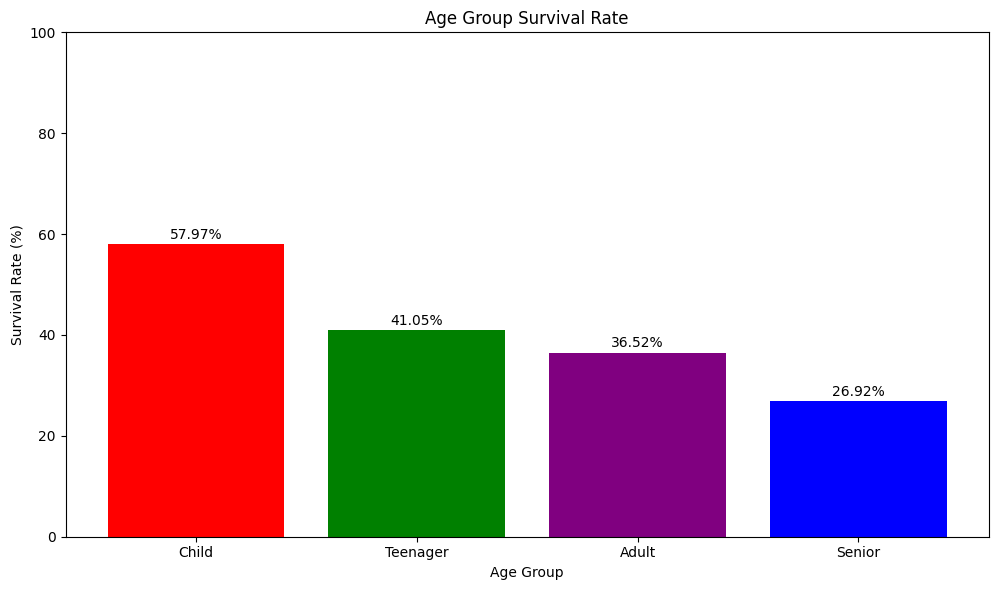

In [153]:
bins = [0, 12, 19, 59, 100]
labels = ["Child", "Teenager", "Adult", "Senior"]

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels
)
survival_rate = (
    df.groupby("Age_Group", observed=True)["Survived"].mean() * 100
)

plt.figure(figsize=(10,6))
plt.bar(
    survival_rate.index,
    survival_rate.values,
    color=["red", "green", "purple", "blue"]
)
for i, value in enumerate(survival_rate.values):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")
plt.title("Age Group Survival Rate")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.tight_layout()
plt.ylim(0, 100)
plt.show()


In [158]:
save = df.to_csv("Clean_Titanic_Data.csv" , index= False)

In [159]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
Age_Group      0
dtype: int64